# Weather vs Energy Consumption — Full Correlation Analysis
**5 Steps:**
1. Pearson Correlation Heatmap
2. Spearman Correlation Heatmap
3. Pearson vs Spearman Bar Chart (each weather var vs energy)
4. Scatter Plots with regression line (top 6 variables)
5. Interaction Terms — cross-variable effects on energy

In [1]:
# =============================================================================
# 1. IMPORTS
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats
from itertools import combinations

# Plot style
plt.rcParams.update({
    'figure.dpi'    : 130,
    'font.size'     : 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10
})

print('Libraries loaded.')

Libraries loaded.


In [2]:
# =============================================================================
# 2. LOAD, MERGE & CLEAN
# =============================================================================
ENERGY_PATH  = '../data/interim/hourly_energy.csv'
WEATHER_PATH = '../data/interim/weather_hourly.csv'

energy_df  = pd.read_csv(ENERGY_PATH)
weather_df = pd.read_csv(WEATHER_PATH)

energy_df['cleaned bucket'] = pd.to_datetime(energy_df['cleaned bucket'])
weather_df['timestamp']     = pd.to_datetime(weather_df['timestamp'])

merged_df = pd.merge(
    energy_df, weather_df,
    left_on='cleaned bucket', right_on='timestamp',
    how='inner'
)
merged_df.dropna(inplace=True)
merged_df.reset_index(drop=True, inplace=True)

TARGET      = 'energy_kwh.1'
DROP_COLS   = ['cleaned bucket', 'timestamp', TARGET]
feature_cols = [c for c in merged_df.select_dtypes(include=np.number).columns
                if c not in DROP_COLS]

# Working dataframe: only numerical cols + target
analysis_df = merged_df[feature_cols + [TARGET]].copy()

print(f'Dataset ready  — rows: {len(analysis_df)}, features: {len(feature_cols)}')
print('Features:', feature_cols)

Dataset ready  — rows: 2207, features: 21
Features: ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']


---
## STEP 1 — Pearson Correlation Heatmap
Shows **linear** correlations between every pair of variables.

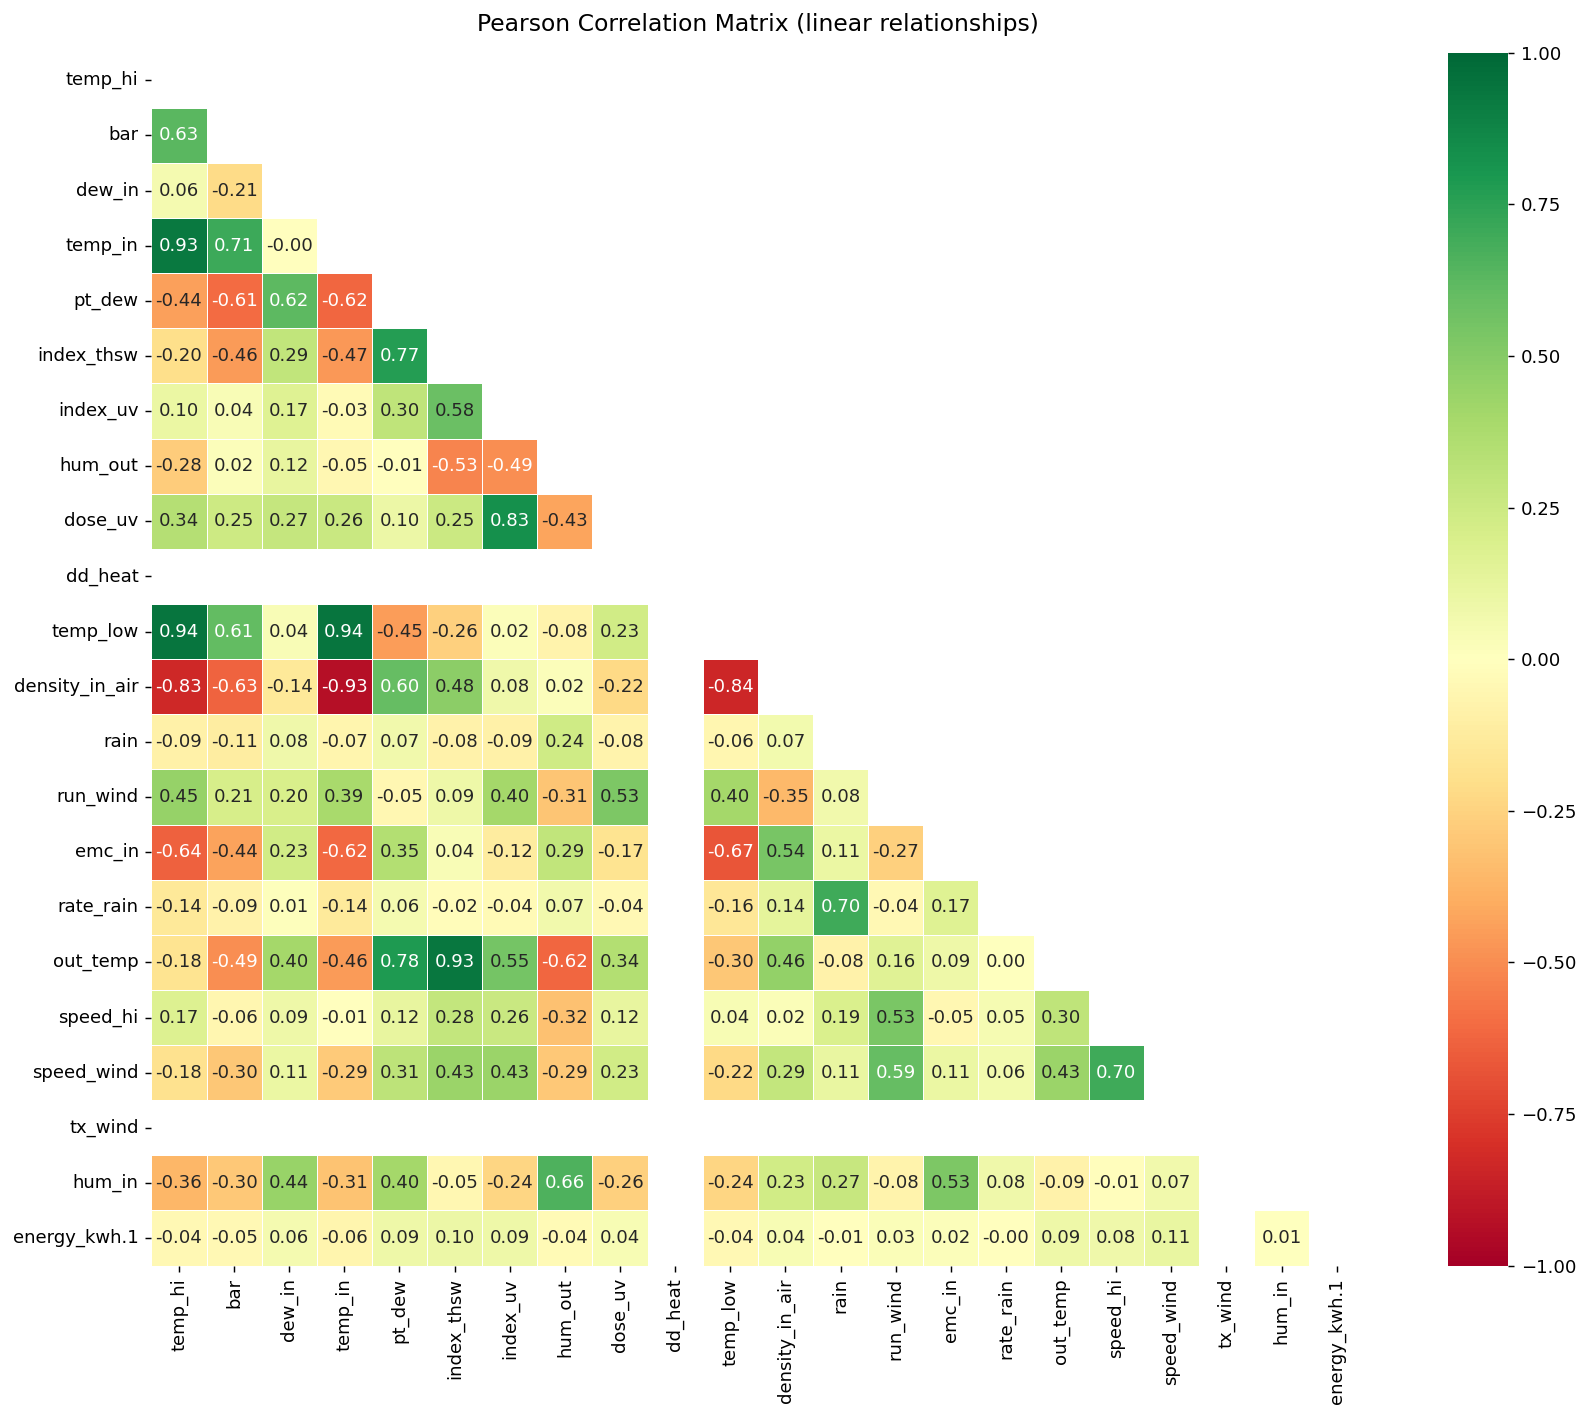


Pearson Correlations with Energy (sorted by |r|):
speed_wind        0.111469
index_thsw        0.097866
out_temp          0.093451
index_uv          0.091585
pt_dew            0.089844
speed_hi          0.080270
temp_in          -0.063205
dew_in            0.056660
bar              -0.046280
density_in_air    0.044752
temp_low         -0.043921
temp_hi          -0.040718
dose_uv           0.040602
hum_out          -0.035274
run_wind          0.030653
emc_in            0.015650
rain             -0.007643
hum_in            0.005643
rate_rain        -0.003418
dd_heat                NaN
tx_wind                NaN


In [3]:
pearson_matrix = analysis_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(pearson_matrix, dtype=bool))   # hide upper triangle

sns.heatmap(
    pearson_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    square=True,
    ax=ax
)
ax.set_title('Pearson Correlation Matrix (linear relationships)', fontsize=13, pad=12)
plt.tight_layout()
plt.savefig('../outputs/figures/pearson_heatmap.png', bbox_inches='tight')
plt.show()

# Print energy correlations sorted
print('\nPearson Correlations with Energy (sorted by |r|):')
energy_pearson = (
    pearson_matrix[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
)
print(pearson_matrix[TARGET].drop(TARGET).loc[energy_pearson.index].to_string())

---
## STEP 2 — Spearman Correlation Heatmap
Captures **monotonic** (not just linear) relationships. Better for skewed variables like rain, UV dose.

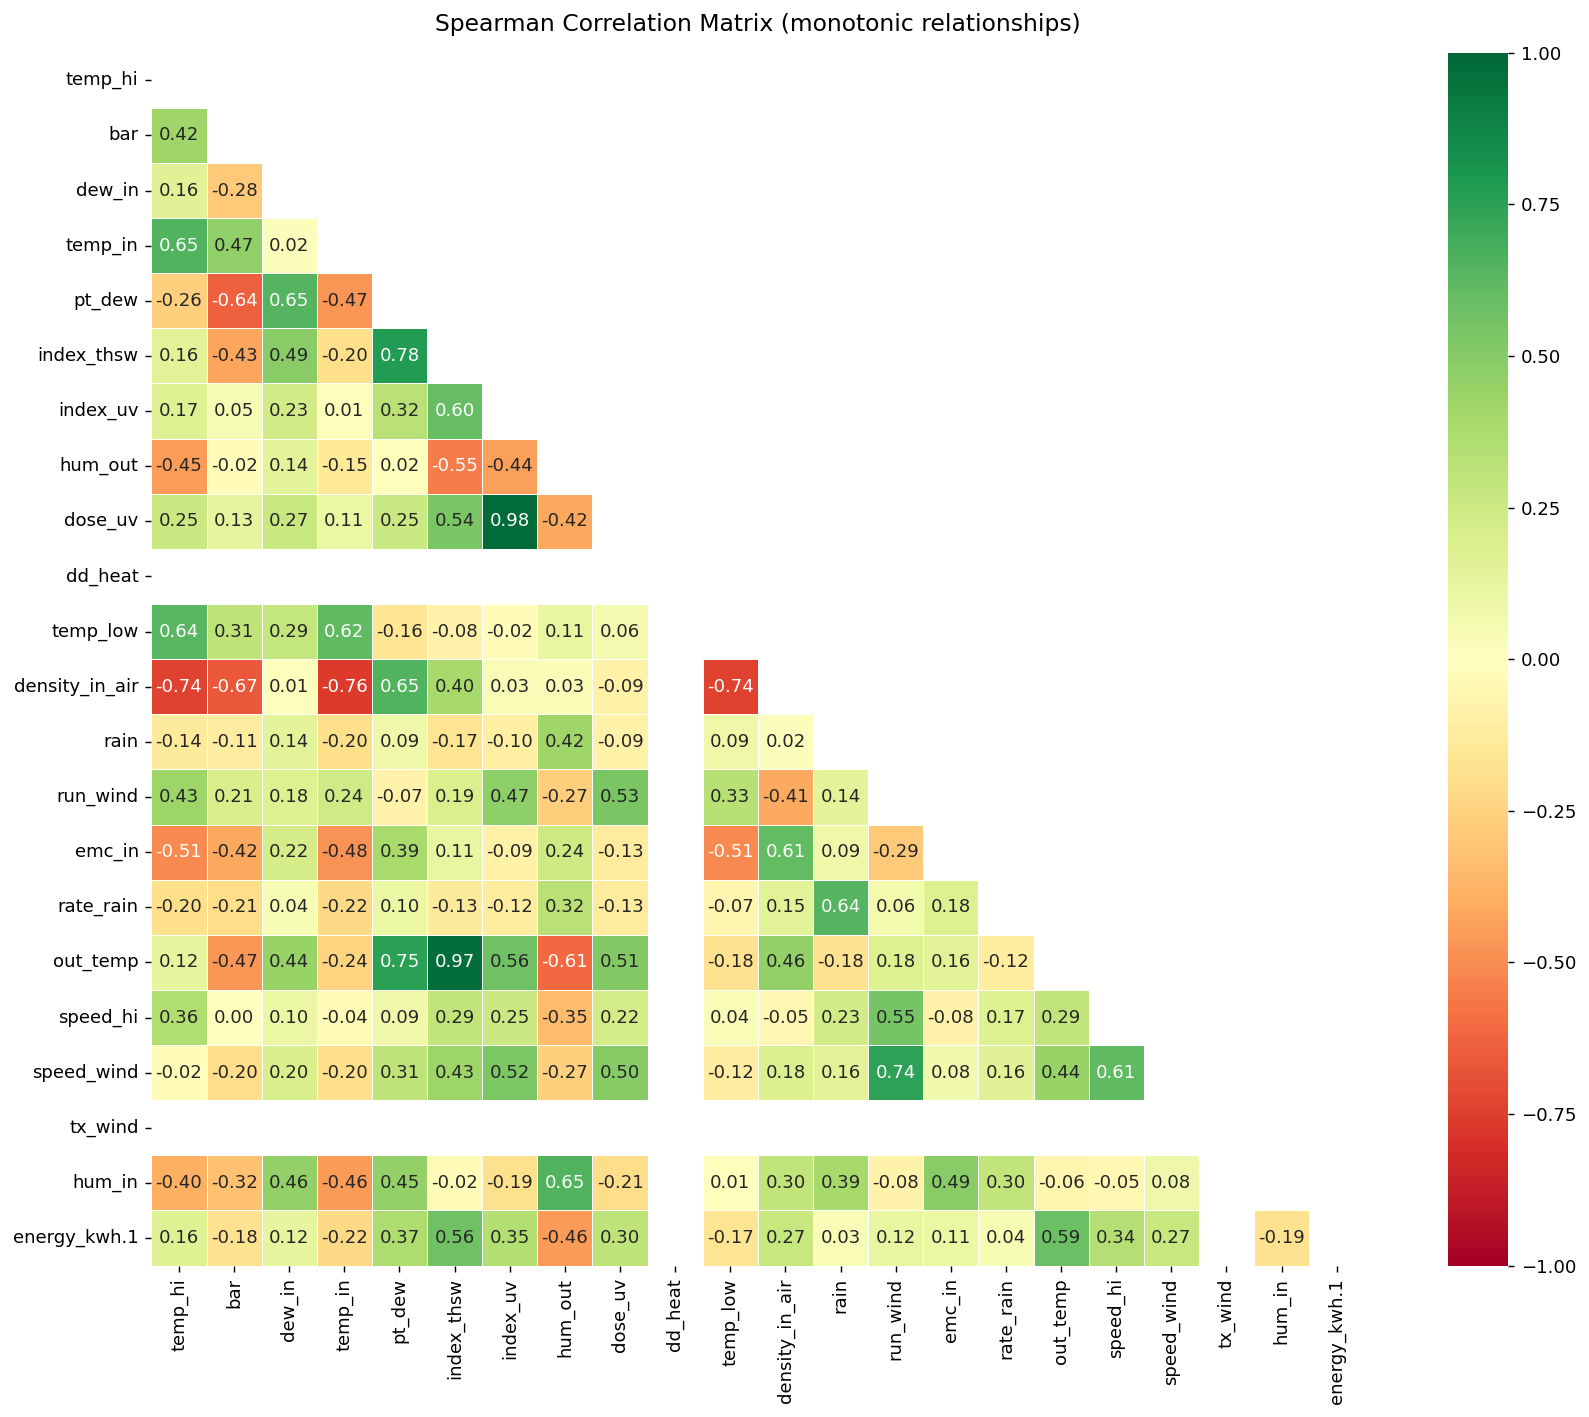


Spearman Correlations with Energy (sorted by |r|):
out_temp          0.585712
index_thsw        0.562952
hum_out          -0.457691
pt_dew            0.370547
index_uv          0.346641
speed_hi          0.337074
dose_uv           0.304868
speed_wind        0.270996
density_in_air    0.270630
temp_in          -0.223266
hum_in           -0.185459
bar              -0.180402
temp_low         -0.165986
temp_hi           0.164127
dew_in            0.118114
run_wind          0.116902
emc_in            0.109127
rate_rain         0.039812
rain              0.031401
dd_heat                NaN
tx_wind                NaN


In [4]:
spearman_matrix = analysis_df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(spearman_matrix, dtype=bool))

sns.heatmap(
    spearman_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    square=True,
    ax=ax
)
ax.set_title('Spearman Correlation Matrix (monotonic relationships)', fontsize=13, pad=12)
plt.tight_layout()
plt.savefig('../outputs/figures/spearman_heatmap.png', bbox_inches='tight')
plt.show()

print('\nSpearman Correlations with Energy (sorted by |r|):')
energy_spearman = (
    spearman_matrix[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
)
print(spearman_matrix[TARGET].drop(TARGET).loc[energy_spearman.index].to_string())

---
## STEP 3 — Pearson vs Spearman Bar Chart
Side-by-side comparison per variable. Large gap = nonlinear effect present.

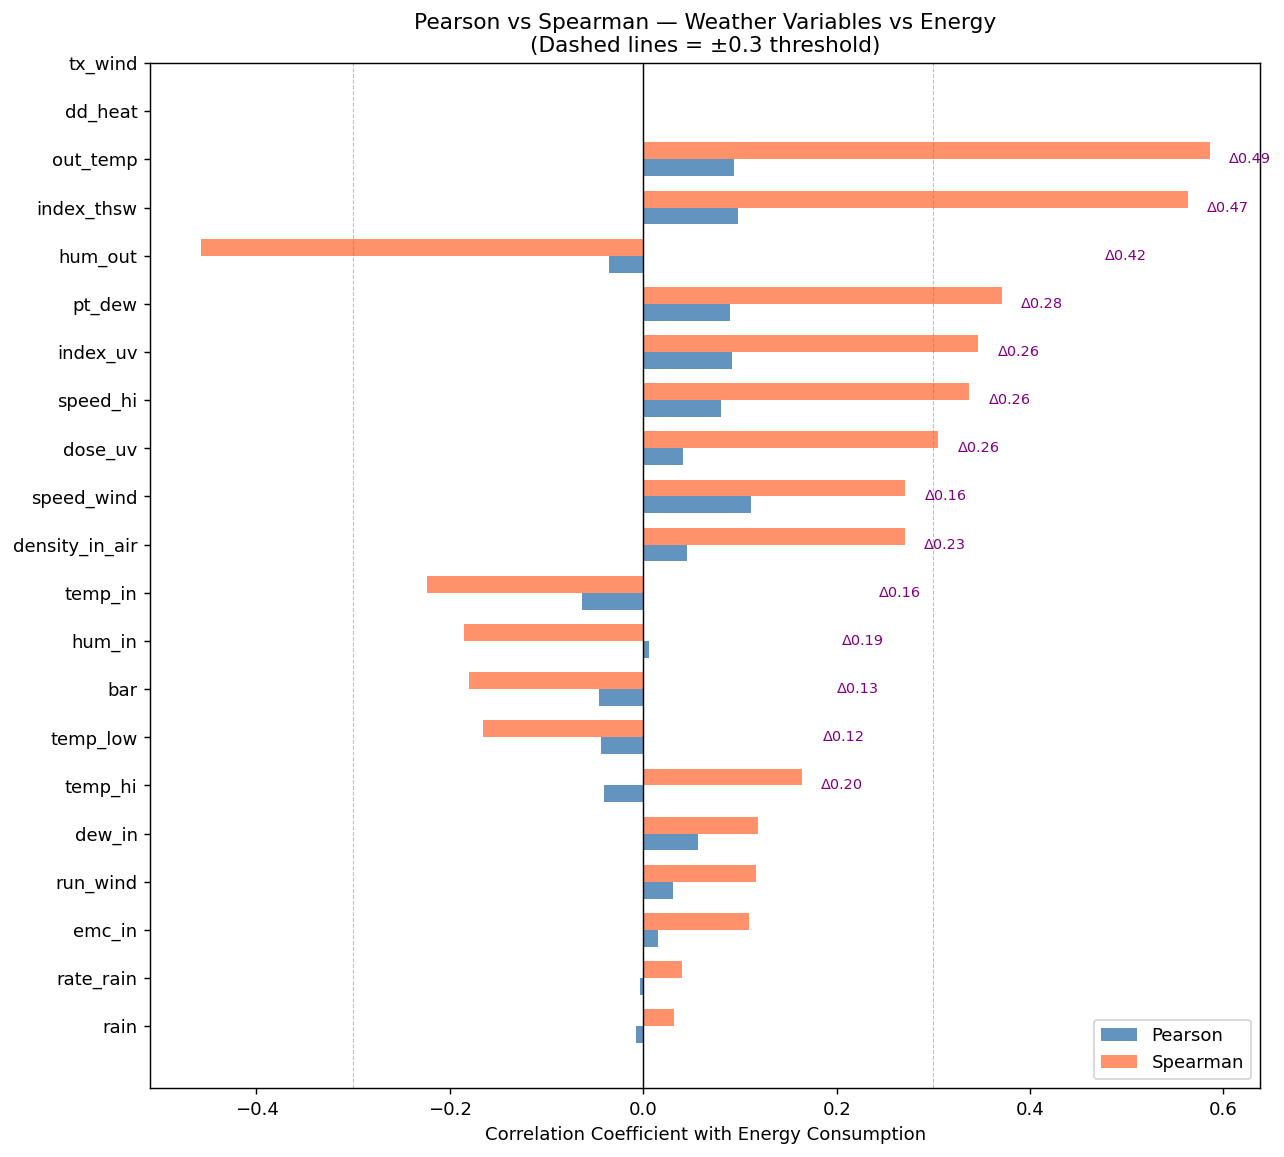


Pearson vs Spearman — Variables with Biggest Gap (nonlinear candidates):
                Pearson  Spearman  Gap (|P-S|)
out_temp         0.0935    0.5857       0.4923
index_thsw       0.0979    0.5630       0.4651
hum_out         -0.0353   -0.4577       0.4224
pt_dew           0.0898    0.3705       0.2807
dose_uv          0.0406    0.3049       0.2643
speed_hi         0.0803    0.3371       0.2568
index_uv         0.0916    0.3466       0.2551
density_in_air   0.0448    0.2706       0.2259
temp_hi         -0.0407    0.1641       0.2048
hum_in           0.0056   -0.1855       0.1911
temp_in         -0.0632   -0.2233       0.1601
speed_wind       0.1115    0.2710       0.1595
bar             -0.0463   -0.1804       0.1341
temp_low        -0.0439   -0.1660       0.1221
emc_in           0.0156    0.1091       0.0935
run_wind         0.0307    0.1169       0.0862
dew_in           0.0567    0.1181       0.0615
rate_rain       -0.0034    0.0398       0.0432
rain            -0.0076    0.0314

In [5]:
pearson_vals  = pearson_matrix[TARGET].drop(TARGET)
spearman_vals = spearman_matrix[TARGET].drop(TARGET)

# Sort by absolute Spearman value
sort_order = spearman_vals.abs().sort_values(ascending=True).index

pearson_sorted  = pearson_vals.loc[sort_order]
spearman_sorted = spearman_vals.loc[sort_order]

y_pos = np.arange(len(sort_order))
height = 0.35

fig, ax = plt.subplots(figsize=(10, 9))

bars1 = ax.barh(y_pos - height/2, pearson_sorted.values,  height,
                color='steelblue', alpha=0.85, label='Pearson')
bars2 = ax.barh(y_pos + height/2, spearman_sorted.values, height,
                color='coral',     alpha=0.85, label='Spearman')

ax.set_yticks(y_pos)
ax.set_yticklabels(sort_order)
ax.axvline(0, color='black', linewidth=0.8)
ax.axvline( 0.3, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)
ax.axvline(-0.3, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlabel('Correlation Coefficient with Energy Consumption')
ax.set_title('Pearson vs Spearman — Weather Variables vs Energy\n(Dashed lines = \u00b10.3 threshold)', fontsize=12)
ax.legend(loc='lower right')

# Annotate the gap where Pearson and Spearman diverge most
for i, feat in enumerate(sort_order):
    gap = abs(spearman_sorted[feat] - pearson_sorted[feat])
    if gap > 0.1:
        ax.text(max(abs(spearman_sorted[feat]), abs(pearson_sorted[feat])) + 0.02,
                i, f'\u0394{gap:.2f}', va='center', fontsize=8, color='purple')

plt.tight_layout()
plt.savefig('../outputs/figures/pearson_vs_spearman_bar.png', bbox_inches='tight')
plt.show()

# Summary table
comparison_df = pd.DataFrame({
    'Pearson' : pearson_vals,
    'Spearman': spearman_vals,
    'Gap (|P-S|)': (pearson_vals - spearman_vals).abs()
}).sort_values('Gap (|P-S|)', ascending=False)

print('\nPearson vs Spearman — Variables with Biggest Gap (nonlinear candidates):')
print(comparison_df.round(4).to_string())

---
## STEP 4 — Scatter Plots for Top 6 Variables
Visual confirmation of the relationship shape with regression line.

Top 6 features by |Spearman| vs energy: ['out_temp', 'index_thsw', 'hum_out', 'pt_dew', 'index_uv', 'speed_hi']


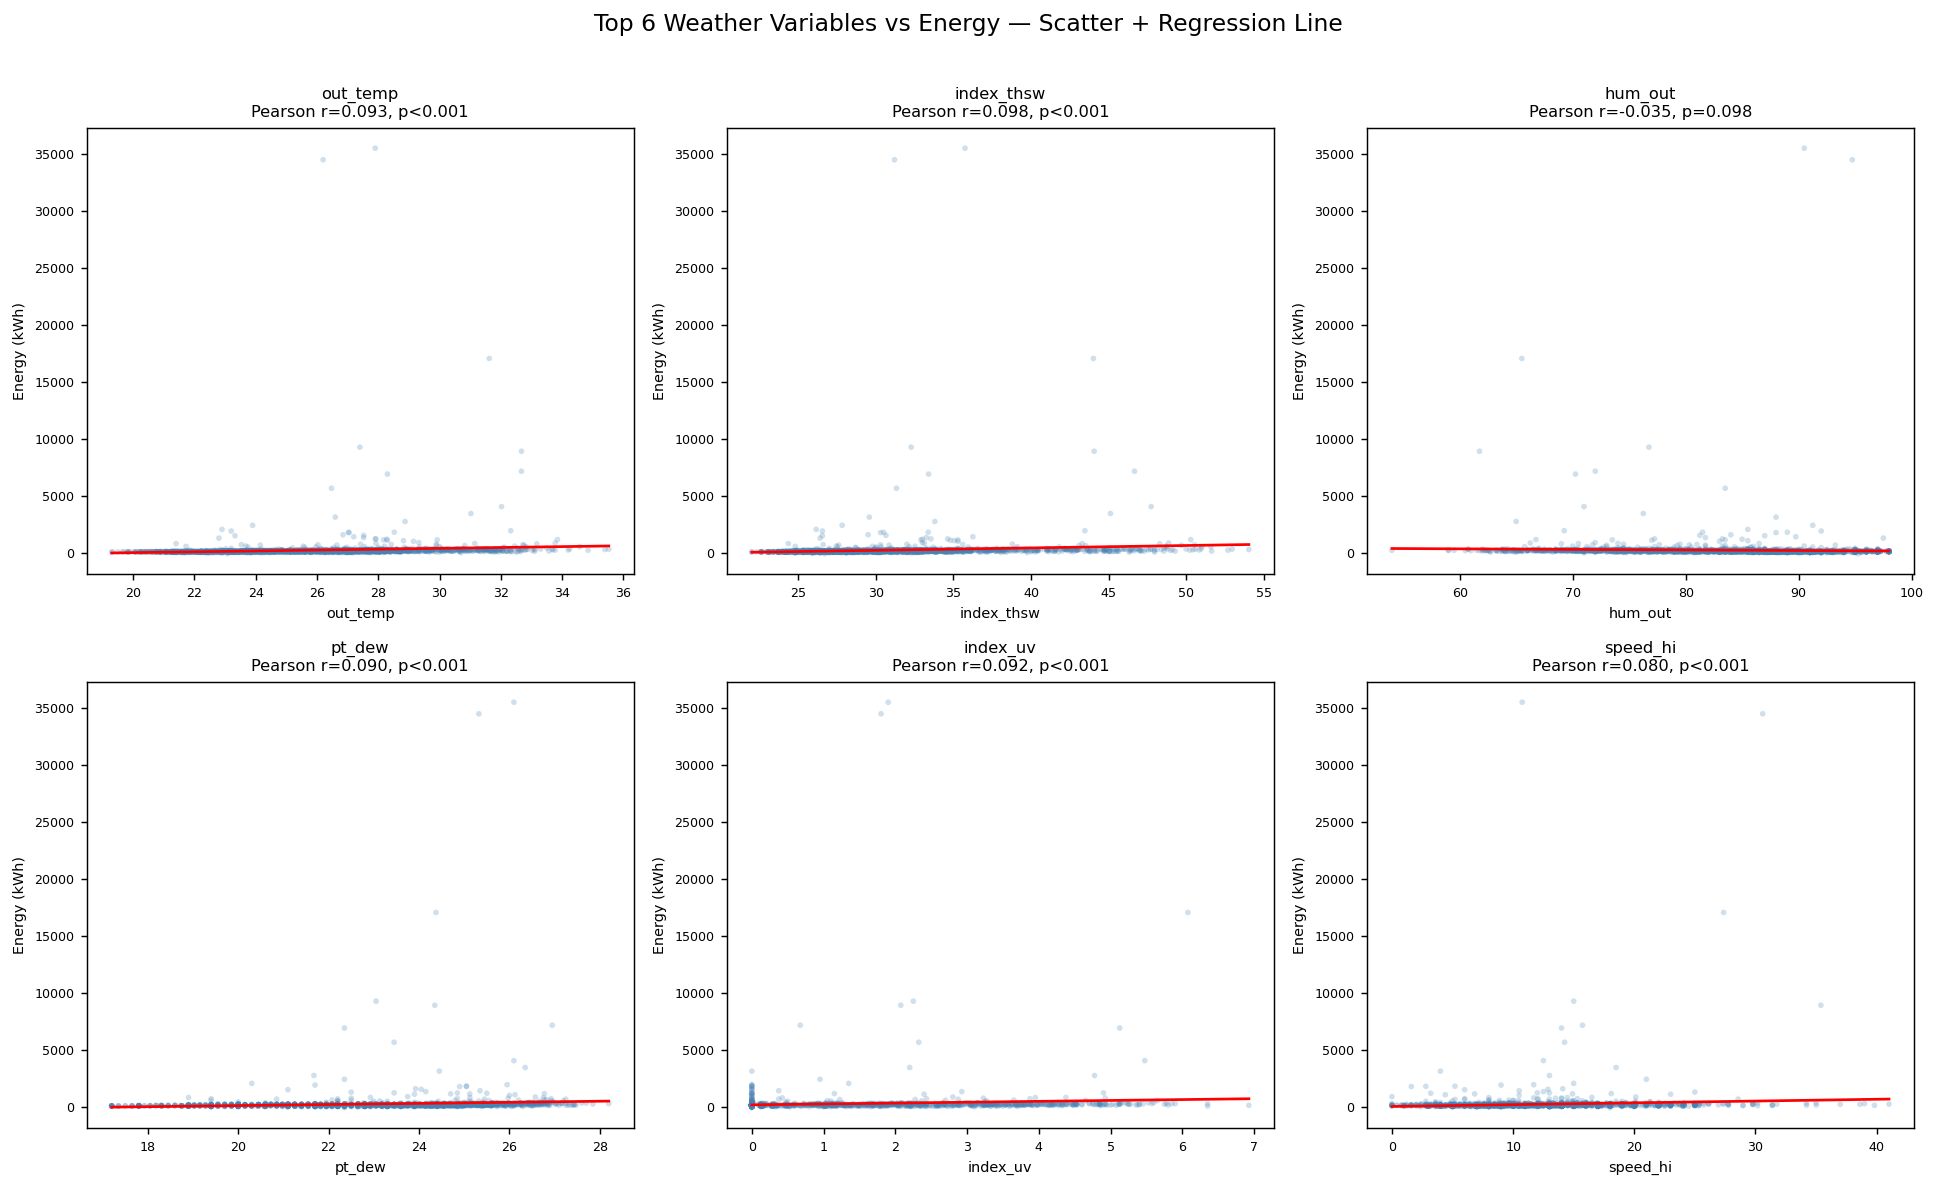

In [6]:
# Pick top 6 by absolute Spearman correlation with energy
top6_features = spearman_vals.abs().sort_values(ascending=False).head(6).index.tolist()
print('Top 6 features by |Spearman| vs energy:', top6_features)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feat in enumerate(top6_features):
    ax = axes[i]
    x_vals = analysis_df[feat].values
    y_vals = analysis_df[TARGET].values

    # Scatter
    ax.scatter(x_vals, y_vals, alpha=0.25, s=10, color='steelblue', edgecolors='none')

    # Regression line
    slope, intercept, r_val, p_val, _ = stats.linregress(x_vals, y_vals)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
    ax.plot(x_line, slope * x_line + intercept, color='red', linewidth=1.5, label='Linear fit')

    # Annotations
    p_label = f'p<0.001' if p_val < 0.001 else f'p={p_val:.3f}'
    ax.set_title(f'{feat}\nPearson r={r_val:.3f}, {p_label}', fontsize=9)
    ax.set_xlabel(feat, fontsize=8)
    ax.set_ylabel('Energy (kWh)', fontsize=8)
    ax.tick_params(labelsize=7)

plt.suptitle('Top 6 Weather Variables vs Energy — Scatter + Regression Line', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/figures/scatter_top6.png', bbox_inches='tight')
plt.show()

---
## STEP 5 — Interaction Terms (Cross-Variable Effects)
Creates pairwise products of all weather features (e.g. `out_temp × hum_out`) 
and correlates each interaction term with energy to find the most impactful combinations.

In [7]:
# =============================================================================
# Build all pairwise interaction terms and correlate with energy
# =============================================================================
interaction_records = []

for feat_a, feat_b in combinations(feature_cols, 2):
    interaction_series = analysis_df[feat_a] * analysis_df[feat_b]

    # Skip constant interactions (zero variance)
    if interaction_series.std() == 0:
        continue

    p_corr, p_pval = stats.pearsonr(interaction_series,  analysis_df[TARGET])
    s_corr, s_pval = stats.spearmanr(interaction_series, analysis_df[TARGET])

    interaction_records.append({
        'Interaction'    : f'{feat_a}  x  {feat_b}',
        'Pearson_r'      : round(p_corr, 4),
        'Pearson_p'      : round(p_pval, 4),
        'Spearman_r'     : round(s_corr, 4),
        'Spearman_p'     : round(s_pval, 4),
        'Abs_Spearman'   : abs(round(s_corr, 4))
    })

interaction_df = (
    pd.DataFrame(interaction_records)
    .sort_values('Abs_Spearman', ascending=False)
    .reset_index(drop=True)
)

print(f'Total interaction terms computed: {len(interaction_df)}')
print('\nTop 20 Cross-Variable Effects on Energy:')
print(interaction_df.drop(columns='Abs_Spearman').head(20).to_string(index=False))

Total interaction terms computed: 190

Top 20 Cross-Variable Effects on Energy:
                  Interaction  Pearson_r  Pearson_p  Spearman_r  Spearman_p
             bar  x  out_temp     0.0934     0.0000      0.5891         0.0
  density_in_air  x  out_temp     0.0933     0.0000      0.5870         0.0
         out_temp  x  tx_wind     0.0935     0.0000      0.5857         0.0
      index_thsw  x  out_temp     0.0976     0.0000      0.5760         0.0
index_thsw  x  density_in_air     0.0971     0.0000      0.5660         0.0
           bar  x  index_thsw     0.0979     0.0000      0.5650         0.0
       index_thsw  x  tx_wind     0.0979     0.0000      0.5630         0.0
        index_thsw  x  emc_in     0.0897     0.0000      0.5419         0.0
          emc_in  x  out_temp     0.0772     0.0003      0.5236         0.0
          temp_in  x  hum_out    -0.0716     0.0008     -0.5087         0.0
          pt_dew  x  out_temp     0.0984     0.0000      0.5063         0.0
        

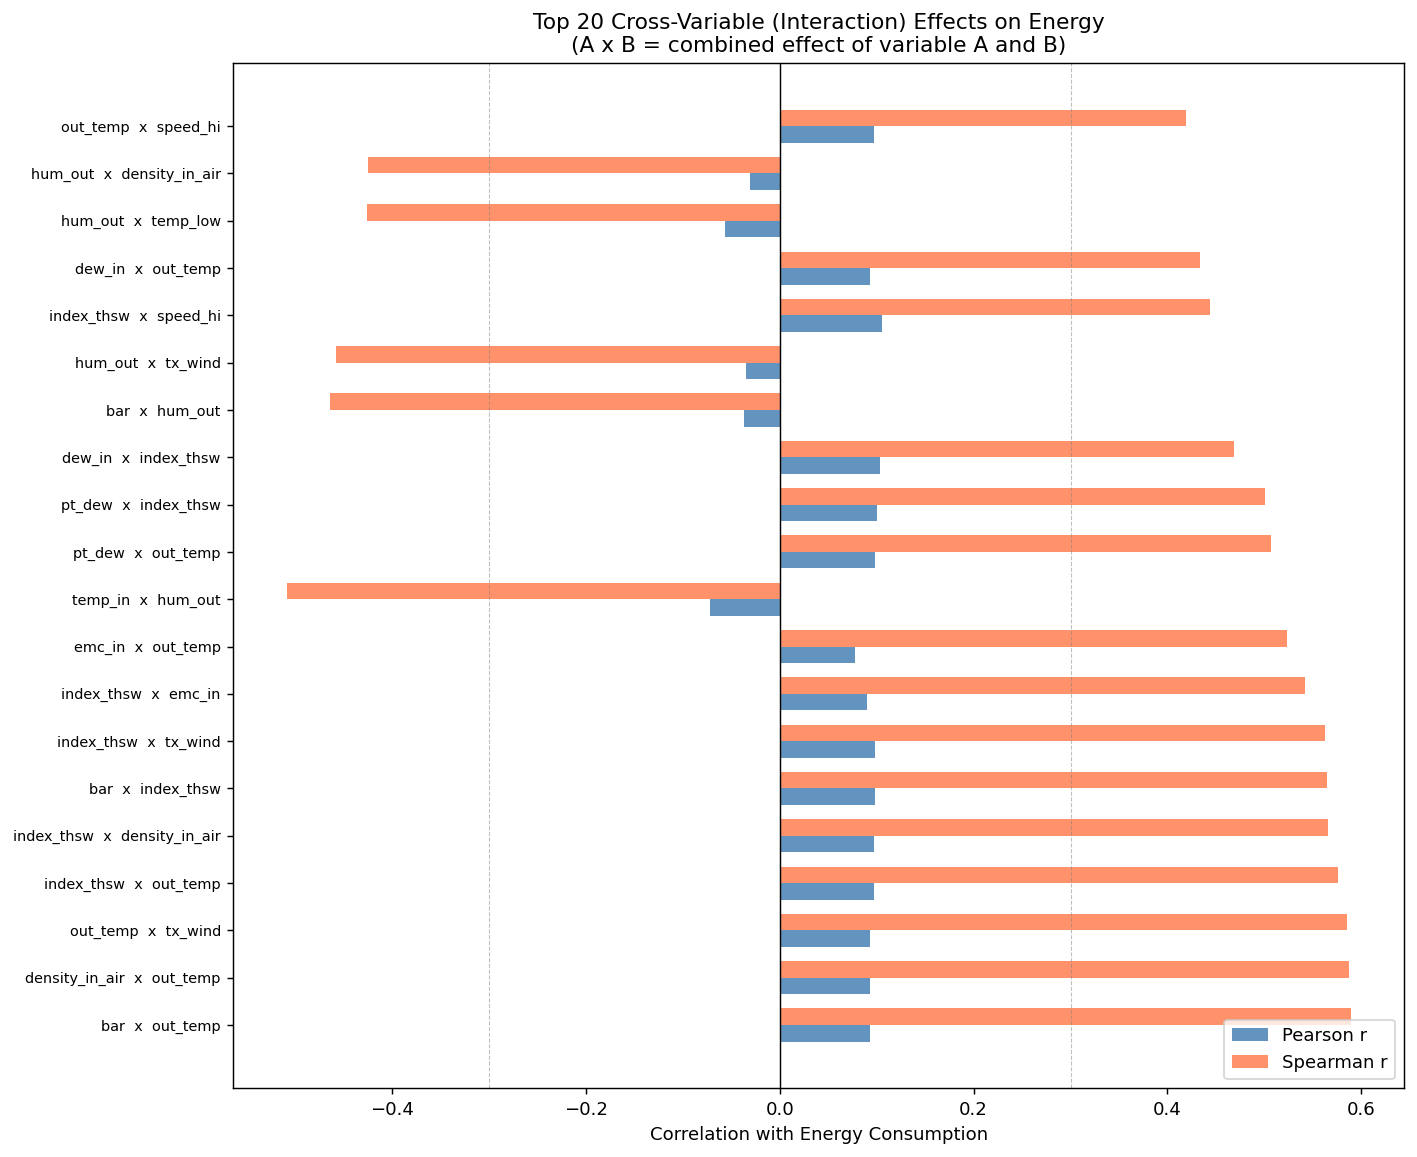

In [8]:
# =============================================================================
# Plot Top 20 Interaction Terms
# =============================================================================
top20 = interaction_df.head(20).copy()

fig, ax = plt.subplots(figsize=(11, 9))
y_pos = np.arange(len(top20))
height = 0.35

ax.barh(y_pos - height/2, top20['Pearson_r'].values,  height,
        color='steelblue', alpha=0.85, label='Pearson r')
ax.barh(y_pos + height/2, top20['Spearman_r'].values, height,
        color='coral',     alpha=0.85, label='Spearman r')

ax.set_yticks(y_pos)
ax.set_yticklabels(top20['Interaction'], fontsize=8)
ax.axvline(0,    color='black', linewidth=0.8)
ax.axvline( 0.3, color='gray',  linewidth=0.6, linestyle='--', alpha=0.5)
ax.axvline(-0.3, color='gray',  linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlabel('Correlation with Energy Consumption')
ax.set_title('Top 20 Cross-Variable (Interaction) Effects on Energy\n(A x B = combined effect of variable A and B)', fontsize=12)
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('../outputs/figures/interaction_terms_bar.png', bbox_inches='tight')
plt.show()

In [9]:
# =============================================================================
# FINAL SUMMARY TABLE — Individual + Interaction, ranked together
# =============================================================================
# Individual variable correlations
individual_summary = pd.DataFrame({
    'Variable'    : spearman_vals.index,
    'Type'        : 'Individual',
    'Pearson_r'   : pearson_vals.values.round(4),
    'Spearman_r'  : spearman_vals.values.round(4),
    'Abs_Spearman': spearman_vals.abs().values.round(4)
})

# Top 10 interaction terms
top_interactions_summary = pd.DataFrame({
    'Variable'    : interaction_df['Interaction'].head(10),
    'Type'        : 'Interaction',
    'Pearson_r'   : interaction_df['Pearson_r'].head(10).values,
    'Spearman_r'  : interaction_df['Spearman_r'].head(10).values,
    'Abs_Spearman': interaction_df['Abs_Spearman'].head(10).values
})

final_summary = (
    pd.concat([individual_summary, top_interactions_summary], ignore_index=True)
    .sort_values('Abs_Spearman', ascending=False)
    .reset_index(drop=True)
    .drop(columns='Abs_Spearman')
)

print('=' * 75)
print('FINAL RANKING — Individual Variables + Top Interaction Terms vs Energy')
print('=' * 75)
print(final_summary.to_string(index=False))

# Export to CSV for reference
final_summary.to_csv('../outputs/tables/correlation_summary.csv', index=False)
interaction_df.drop(columns='Abs_Spearman').to_csv('../outputs/tables/all_interaction_correlations.csv', index=False)
print('\nSaved: correlation_summary.csv, all_interaction_correlations.csv')

FINAL RANKING — Individual Variables + Top Interaction Terms vs Energy
                     Variable        Type  Pearson_r  Spearman_r
             bar  x  out_temp Interaction     0.0934      0.5891
  density_in_air  x  out_temp Interaction     0.0933      0.5870
                     out_temp  Individual     0.0935      0.5857
         out_temp  x  tx_wind Interaction     0.0935      0.5857
      index_thsw  x  out_temp Interaction     0.0976      0.5760
index_thsw  x  density_in_air Interaction     0.0971      0.5660
           bar  x  index_thsw Interaction     0.0979      0.5650
       index_thsw  x  tx_wind Interaction     0.0979      0.5630
                   index_thsw  Individual     0.0979      0.5630
        index_thsw  x  emc_in Interaction     0.0897      0.5419
          emc_in  x  out_temp Interaction     0.0772      0.5236
          temp_in  x  hum_out Interaction    -0.0716     -0.5087
                      hum_out  Individual    -0.0353     -0.4577
                   